# Kriging Ordinario: precipitación total anual en el Altiplano de Puno
**Curso:** Estadística Espacial · **Actividad de Clase**

**Objetivo:** aplicar Kriging Ordinario (KO) a la precipitación total anual de 23 estaciones del SENAMHI en Puno, obtener un mapa continuo de precipitación y su incertidumbre, y evaluar el modelo con validación cruzada.

**Datos:** `estaciones_precipitacion_puno.csv` (extraído de la Tabla 2 del estudio de caracterización climática de las cuencas Coata e Ilave, SENAMHI – Dirección Regional Puno; promedios 1965–2012; UTM WGS84 zona 19S).

**Requisitos:** `pip install numpy pandas scipy matplotlib`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit
from scipy.spatial import ConvexHull, Delaunay
from scipy.spatial.distance import pdist, cdist
plt.rcParams.update({'font.size': 9})

## 1. Lectura de datos
Las coordenadas se pasan de metros a kilómetros para que las distancias del semivariograma sean más legibles.

In [2]:
d = pd.read_csv('estaciones_precipitacion_puno.csv')
x = d['este_utm_m'].values / 1000
y = d['norte_utm_m'].values / 1000
z = d['precip_anual_mm'].values.astype(float)
XY = np.c_[x, y]
n = len(z)
d

,estacion,este_utm_m,norte_utm_m,latitud,longitud,altitud_msnm,precip_anual_mm
0,Arapa,379823,8326267,-15.13653,-70.11850,3892,688
1,Ayaviri,328602,8355116,-14.87294,-70.59317,3921,689
2,Cabanillas,355675,8270502,-15.63933,-70.34644,3877,670
3,Capachica,409496,8273379,-15.61583,-69.84428,3827,800
4,Capazo,421758,8099499,-17.18800,-69.73578,4470,548
5,Chuquibambilla,313519,8364727,-14.78506,-70.73264,3899,724
6,Desaguadero,495691,8168147,-16.56878,-69.04039,3813,731
7,Ilave,430990,8221164,-16.08853,-69.64528,3837,706
8,Juli,450813,8208437,-16.20406,-69.46019,3814,881
9,Juliaca,374843,8289717,-15.46667,-70.16667,3828,652


## 2. Análisis exploratorio
El KO funciona mejor si la variable no está muy sesgada. Revisamos estadísticos y normalidad (Shapiro-Wilk).

In [3]:
print(d['precip_anual_mm'].describe().round(1))
print('\nAsimetría:', round(stats.skew(z), 3))
sw = stats.shapiro(z)
print('Shapiro-Wilk: W = %.3f, p = %.3f' % (sw.statistic, sw.pvalue))

count     23.0
mean     717.4
std       96.7
min      518.0
25%      663.0
50%      724.0
75%      787.5
max      887.0
Name: precip_anual_mm, dtype: float64

Asimetría: -0.24
Shapiro-Wilk: W = 0.980, p = 0.904


p > 0.05 → no se rechaza normalidad; trabajamos con la variable original, sin transformar.

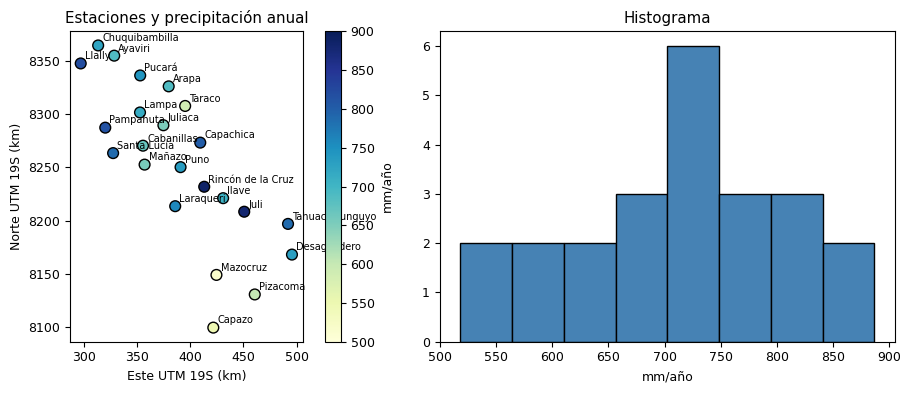

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sc = ax[0].scatter(x, y, c=z, cmap='YlGnBu', s=60, edgecolor='k', vmin=500, vmax=900)
for i, t in enumerate(d['estacion']):
    ax[0].annotate(t, (x[i], y[i]), xytext=(3, 3), textcoords='offset points', fontsize=7)
ax[0].set_aspect('equal'); ax[0].set_xlabel('Este UTM 19S (km)'); ax[0].set_ylabel('Norte UTM 19S (km)')
ax[0].set_title('Estaciones y precipitación anual'); plt.colorbar(sc, ax=ax[0], label='mm/año')
ax[1].hist(z, bins=8, color='steelblue', edgecolor='k'); ax[1].set_xlabel('mm/año'); ax[1].set_title('Histograma')
plt.tight_layout(); plt.show()

## 3. Semivariograma empírico (Matheron)
$$\hat\gamma(h)=\frac{1}{2N(h)}\sum_{N(h)}\left[Z(s_i)-Z(s_i+h)\right]^2$$
Usamos 10 clases de distancia hasta la mitad de la distancia máxima y descartamos clases con menos de 5 pares.

In [5]:
h = pdist(XY)                     # distancias entre todos los pares
g = 0.5 * pdist(z[:, None])**2    # semivarianza de cada par
hmax = h.max() / 2
edges = np.linspace(0, hmax, 11)
hc, gc, nc = [], [], []
for i in range(10):
    m = (h > edges[i]) & (h <= edges[i+1])
    if m.sum() >= 5:
        hc.append(h[m].mean()); gc.append(g[m].mean()); nc.append(m.sum())
hc, gc, nc = map(np.array, (hc, gc, nc))
var = z.var(ddof=1)
pd.DataFrame({'h_km': hc.round(1), 'gamma_mm2': gc.round(0), 'n_pares': nc})

,h_km,gamma_mm2,n_pares
0,23.2,4666.0,10
1,35.6,5046.0,26
2,51.1,5152.0,20
3,63.8,9410.0,23
4,78.6,12351.0,31
5,93.5,5972.0,20
6,109.1,15139.0,22
7,121.0,11051.0,12
8,135.5,9295.0,14


## 4. Ajuste de modelos teóricos
Esférico, exponencial y gaussiano, por mínimos cuadrados ponderados por número de pares. En el exponencial y gaussiano `a` es el alcance práctico (95 % de la meseta).

Esférico     pepita =     66.9  meseta parcial =  11473.4  alcance =  115.1 km
Exponencial  pepita =      0.0  meseta parcial =  13870.8  alcance =  198.3 km
Gaussiano    pepita =   2057.3  meseta parcial =   9535.8  alcance =   99.7 km


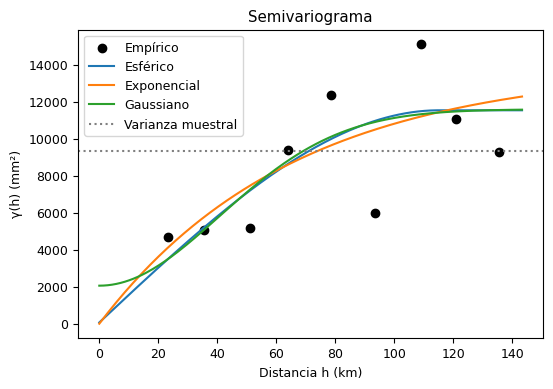

In [6]:
def esferico(h, c0, c, a):    return np.where(h < a, c0 + c*(1.5*h/a - 0.5*(h/a)**3), c0 + c)
def exponencial(h, c0, c, a): return c0 + c*(1 - np.exp(-3*h/a))
def gaussiano(h, c0, c, a):   return c0 + c*(1 - np.exp(-3*(h/a)**2))
modelos = {'Esférico': esferico, 'Exponencial': exponencial, 'Gaussiano': gaussiano}

params = {}
for k, f in modelos.items():
    p, _ = curve_fit(f, hc, gc, p0=[0.1*var, var, hmax/2], sigma=1/np.sqrt(nc),
                     bounds=([0, 0, 10], [2*var, 3*var, 600]), maxfev=20000)
    params[k] = p
    print(f'{k:12s} pepita = {p[0]:8.1f}  meseta parcial = {p[1]:8.1f}  alcance = {p[2]:6.1f} km')

hh = np.linspace(0, hmax, 200)
plt.figure(figsize=(6, 4))
plt.scatter(hc, gc, c='k', label='Empírico')
for k, f in modelos.items(): plt.plot(hh, f(hh, *params[k]), label=k)
plt.axhline(var, ls=':', c='gray', label='Varianza muestral')
plt.xlabel('Distancia h (km)'); plt.ylabel('γ(h) (mm²)'); plt.legend(); plt.title('Semivariograma'); plt.show()

## 5. Kriging Ordinario
Sistema de ecuaciones (con multiplicador de Lagrange $\mu$ para que $\sum\lambda_i=1$):
$$\begin{bmatrix}\Gamma & \mathbf 1\\ \mathbf 1^T & 0\end{bmatrix}\begin{bmatrix}\boldsymbol\lambda\\ \mu\end{bmatrix}=\begin{bmatrix}\boldsymbol\gamma_0\\ 1\end{bmatrix},\qquad \sigma^2_{KO}=\boldsymbol\lambda^T\boldsymbol\gamma_0+\mu$$

In [7]:
def kriging_ordinario(f, p, XYo, zo, XYp):
    No = len(zo)
    G = f(cdist(XYo, XYo), *p); np.fill_diagonal(G, 0)   # γ(0) = 0
    A = np.ones((No+1, No+1)); A[:No, :No] = G; A[No, No] = 0
    B = np.vstack([f(cdist(XYo, XYp), *p), np.ones(len(XYp))])
    W = np.linalg.solve(A, B)          # pesos λ y μ
    zp = W[:No].T @ zo                 # predicción
    s2 = (W * B).sum(0)                # varianza de kriging
    return zp, s2

## 6. Validación cruzada (leave-one-out)
Se quita cada estación, se estima con las demás y se compara. MSDR ≈ 1 indica que la varianza de kriging representa bien el error real.

In [8]:
resumen, loo = [], {}
for k, f in modelos.items():
    pr, sv = np.zeros(n), np.zeros(n)
    for i in range(n):
        idx = np.arange(n) != i
        a, b = kriging_ordinario(f, params[k], XY[idx], z[idx], XY[i:i+1])
        pr[i], sv[i] = a[0], b[0]
    e = pr - z; loo[k] = pr
    resumen.append([k, e.mean(), np.sqrt((e**2).mean()), np.abs(e).mean(), np.mean(e**2/sv), np.corrcoef(pr, z)[0, 1]])
cv = pd.DataFrame(resumen, columns=['Modelo', 'ME', 'RMSE', 'MAE', 'MSDR', 'r']).round(2)
mejor = cv.loc[cv['RMSE'].idxmin(), 'Modelo']
print('Modelo seleccionado:', mejor)
cv

Modelo seleccionado: Exponencial


,Modelo,ME,RMSE,MAE,MSDR,r
0,Esférico,-1.08,81.51,62.28,1.56,0.52
1,Exponencial,-0.77,81.36,62.32,1.21,0.51
2,Gaussiano,-0.09,82.20,62.64,1.57,0.51


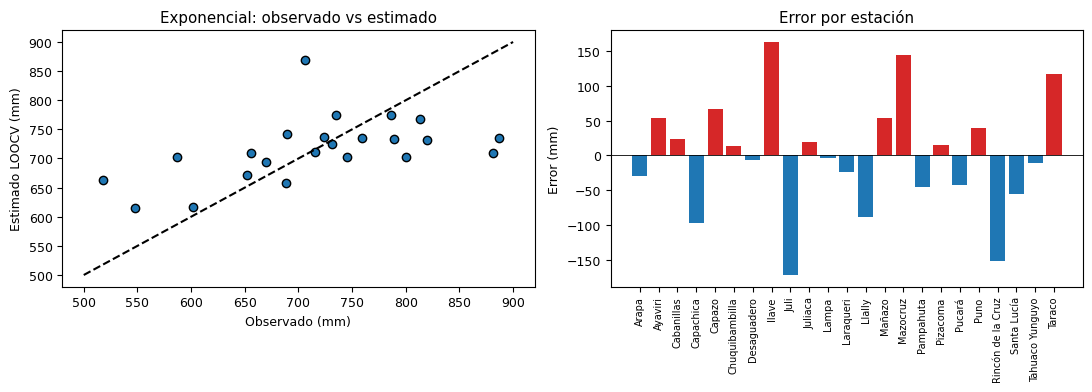

In [9]:
e = loo[mejor] - z
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(z, loo[mejor], edgecolor='k'); ax[0].plot([500, 900], [500, 900], 'k--')
ax[0].set_xlabel('Observado (mm)'); ax[0].set_ylabel('Estimado LOOCV (mm)'); ax[0].set_title(f'{mejor}: observado vs estimado')
ax[1].bar(d['estacion'], e, color=np.where(e > 0, 'tab:red', 'tab:blue')); ax[1].axhline(0, c='k', lw=.6)
ax[1].tick_params(axis='x', rotation=90, labelsize=7); ax[1].set_ylabel('Error (mm)'); ax[1].set_title('Error por estación')
plt.tight_layout(); plt.show()

## 7. Mapa de predicción e incertidumbre
Grilla de 220 × 260 nodos recortada a la envolvente convexa de las estaciones (no se extrapola fuera de la red).

Predicción: 520 – 882 mm/año
Desv. estándar de kriging: 7 – 93 mm


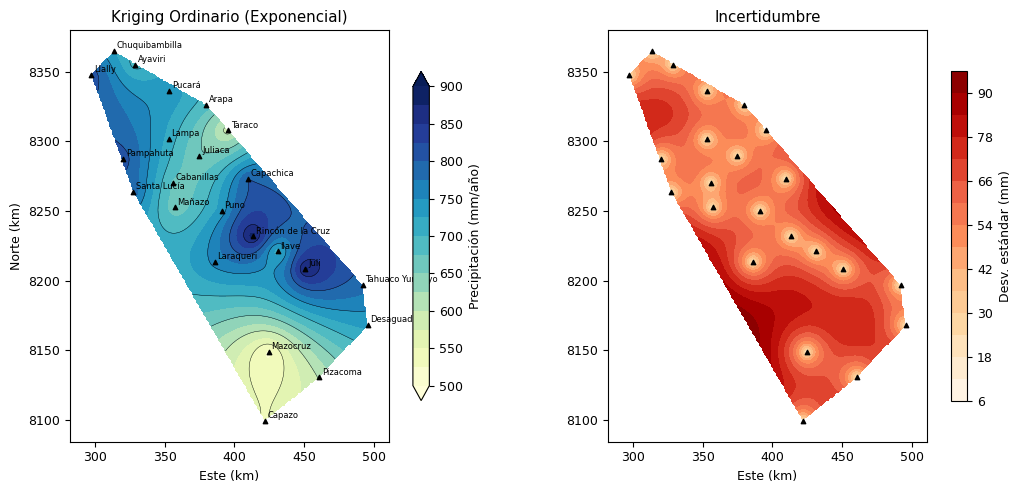

In [10]:
f, p = modelos[mejor], params[mejor]
pad = 15
gx = np.linspace(x.min()-pad, x.max()+pad, 220); gy = np.linspace(y.min()-pad, y.max()+pad, 260)
GX, GY = np.meshgrid(gx, gy); P = np.c_[GX.ravel(), GY.ravel()]
zp, s2 = kriging_ordinario(f, p, XY, z, P)
dentro = (Delaunay(XY[ConvexHull(XY).vertices]).find_simplex(P) >= 0).reshape(GX.shape)
ZP = np.where(dentro, zp.reshape(GX.shape), np.nan)
SD = np.where(dentro, np.sqrt(np.clip(s2, 0, None)).reshape(GX.shape), np.nan)
print('Predicción: %.0f – %.0f mm/año' % (np.nanmin(ZP), np.nanmax(ZP)))
print('Desv. estándar de kriging: %.0f – %.0f mm' % (np.nanmin(SD), np.nanmax(SD)))

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
c1 = ax[0].contourf(GX, GY, ZP, levels=np.arange(500, 925, 25), cmap='YlGnBu', extend='both')
ax[0].contour(GX, GY, ZP, levels=np.arange(550, 900, 50), colors='k', linewidths=.3)
c2 = ax[1].contourf(GX, GY, SD, levels=15, cmap='OrRd')
for a, c, lab in zip(ax, [c1, c2], ['Precipitación (mm/año)', 'Desv. estándar (mm)']):
    a.scatter(x, y, c='k', s=10, marker='^'); a.set_aspect('equal'); a.set_xlabel('Este (km)'); plt.colorbar(c, ax=a, label=lab, shrink=.8)
for i, t in enumerate(d['estacion']):
    ax[0].annotate(t, (x[i], y[i]), xytext=(2, 2), textcoords='offset points', fontsize=6)
ax[0].set_ylabel('Norte (km)'); ax[0].set_title(f'Kriging Ordinario ({mejor})'); ax[1].set_title('Incertidumbre')
plt.tight_layout(); plt.show()

## 8. Interpretación
- **Dependencia espacial:** el semivariograma crece hasta ~80 km; estaciones cercanas tienen lluvias similares. El modelo **exponencial** (pepita ≈ 0) dio el menor RMSE (≈81 mm), error medio ≈ 0 y MSDR más cercano a 1.
- **Patrón espacial:** núcleo húmedo alrededor del lago Titicaca (Puno, Rincón de la Cruz, Juli, Yunguyo: 750–880 mm), zona húmeda de altura al noroeste (Llally, Pampahuta, Santa Lucía) y gradiente seco hacia el sur (Mazocruz, Capazo, Pizacoma: < 600 mm).
- **Incertidumbre:** mínima junto a las estaciones y máxima (~90 mm) en el suroeste y entre Ilave y Desaguadero: ahí convendría instalar más estaciones.
- **Validación:** RMSE (81 mm) < desviación estándar (97 mm): el KO mejora frente a usar la media. Como todo kriging, suaviza los extremos (Juli, Rincón de la Cruz, Mazocruz).
- **Limitación:** con solo 23 estaciones y media constante; incluir altitud o distancia al lago (kriging con deriva externa / cokriging) podría mejorar la estimación.